# 1. Project Title: Air Quality Index (AQI) Analysis in India
**Course:** Data Analysis and Visualization Using Python (CUTM1018)
**Domain:** Environment & Climate
**Submitted By:** PRIYANKA BARIK (Roll No:250301370201)

### Abstract
This study analyzes daily atmospheric pollutant concentrations across major Indian urban centers. We investigate the relationship between primary pollutants (PM2.5, PM10, NO2, SO2, CO) and the composite Air Quality Index (AQI), perform outlier detection, and build an interactive dashboard for urban air trend comparison.

# 2. Problem Statement & Objectives
- **Problem Statement:** Rapid industrialization and vehicular growth have led to severe air degradation across urban India. Identifying primary drivers is essential for targeted environmental governance.
- **Objectives:**
  1. Profile missing sensor records and apply appropriate data imputation methods.
  2. Determine the pollutant most strongly correlated with extreme AQI conditions.
  3. Rank the top 10 most polluted cities in India by mean AQI.
  4. Develop an interactive Plotly Dash analytical application.

# 3. Data Collection & Dataset Description
The dataset is sourced from the Central Pollution Control Board (CPCB) / Kaggle repository. It comprises historical city-level daily air metrics.
- `City`: Monitored metropolitan area
- `Date`: Record date (2015–2020)
- `PM2.5`, `PM10`: Fine inhalable particulate matter ($\mu g/m^3$)
- `NO2`, `SO2`, `CO`, `O3`: Gaseous pollutant concentrations
- `AQI`: Computed National Air Quality Index
- `AQI_Bucket`: Qualitative category (Good to Severe)
-

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

# Load dataset from the data folder
df = pd.read_csv('city_day.csv')
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 29531 rows, 16 columns


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


# 5. Data Cleaning and Preprocessing
Missing sensor values are addressed by imputing continuous numeric fields with their respective medians and categorical indicators with modes. Duplicate observations are purged, and a cleaned copy is saved for the web application.

In [4]:
# Check missing values
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_count, 'Percentage': missing_percent})
display(missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False))

# Impute numeric features with median
for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())

# Impute categorical features with mode
for col in df.select_dtypes(include='object').columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Remove duplicates
print(f"Duplicates removed: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)

# Save cleaned data file for Dash
df.to_csv('cleaned_aqi.csv', index=False)
print("Data cleaning complete. Saved to cleaned_aqi.csv")

,Missing Count,Percentage
Xylene,18109,61.322001
PM10,11140,37.723071
NH3,10328,34.973418
Toluene,8041,27.229014
Benzene,5623,19.041008
AQI,4681,15.851139
AQI_Bucket,4681,15.851139
PM2.5,4598,15.570079
NOx,4185,14.171549
O3,4022,13.619586


Duplicates removed: 0
Data cleaning complete. Saved to cleaned_aqi.csv


# 6. Outlier Detection (IQR Method)
Using the Interquartile Range (IQR) technique, we identify readings lying outside $1.5 \times \text{IQR}$ beyond the first and third quartiles.

In [5]:
def check_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return data[(data[column] < lower_bound) | (data[column] > upper_bound)]

for col in ['PM2.5', 'PM10', 'AQI']:
    if col in df.columns:
        outliers = check_outliers(df, col)
        print(f"{col}: {len(outliers)} outliers detected ({len(outliers)/len(df)*100:.2f}%)")

PM2.5: 2736 outliers detected (9.26%)
PM10: 5322 outliers detected (18.02%)
AQI: 3192 outliers detected (10.81%)


# 7. Exploratory Data Analysis & Visualizations
In this section, we examine pollutant relationships, identify the most polluted locations, and plot distributions. All output figures are saved directly to the `reports/` folder at 150 DPI.

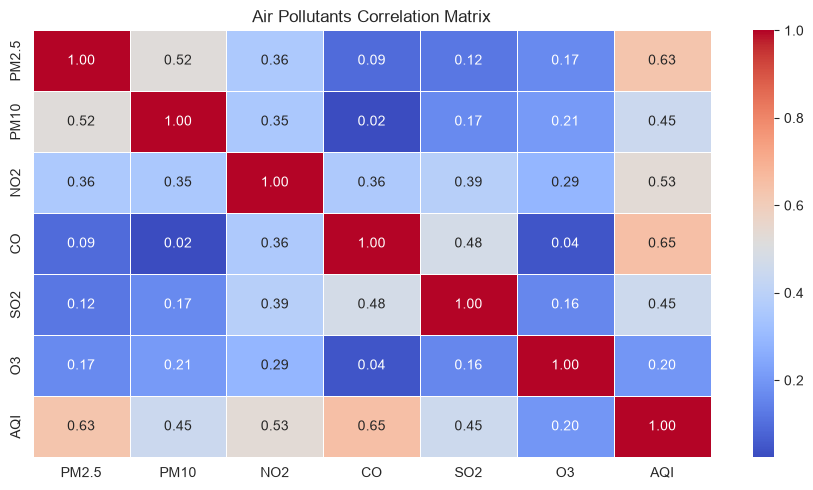

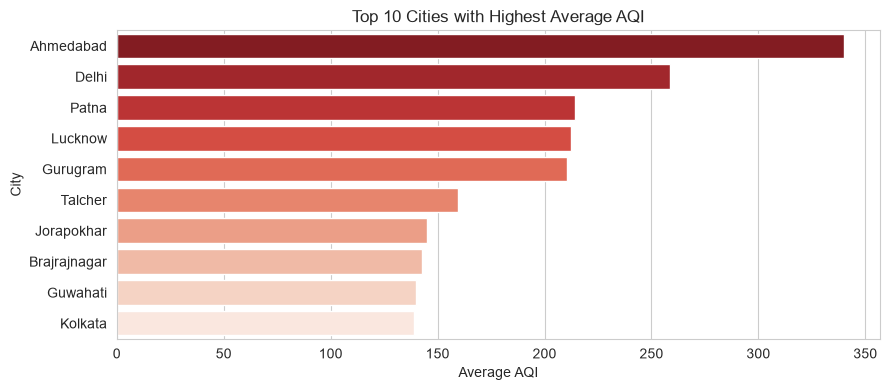

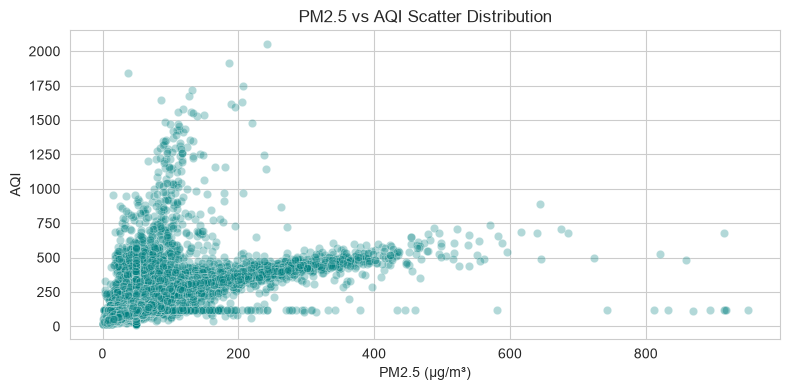

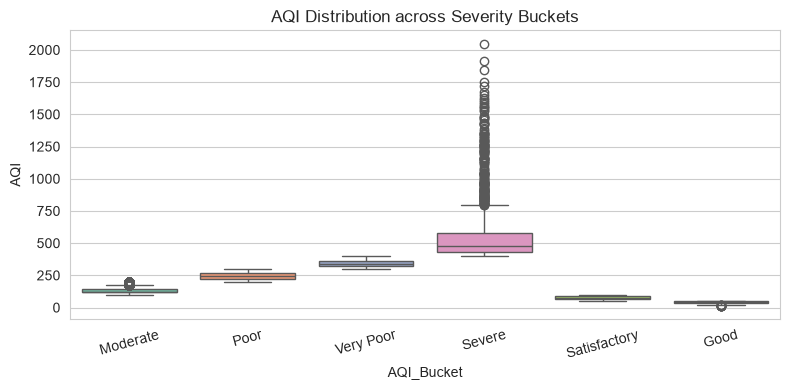

In [6]:
# 1. Feature Correlation Heatmap
cols = [c for c in ['PM2.5', 'PM10', 'NO2', 'CO', 'SO2', 'O3', 'AQI'] if c in df.columns]
plt.figure(figsize=(9, 5))
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Air Pollutants Correlation Matrix')
plt.tight_layout()
plt.savefig('reports/1_correlation_heatmap.png', dpi=150)
plt.show()

# 2. Bar Chart: Top 10 Most Polluted Cities
top_cities = df.groupby('City')['AQI'].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 4))
sns.barplot(x=top_cities.values, y=top_cities.index, palette='Reds_r')
plt.title('Top 10 Cities with Highest Average AQI')
plt.xlabel('Average AQI')
plt.ylabel('City')
plt.tight_layout()
plt.savefig('reports/2_top_cities_aqi.png', dpi=150)
plt.show()

# 3. Scatter Plot: PM2.5 vs AQI
plt.figure(figsize=(8, 4))
sns.scatterplot(x='PM2.5', y='AQI', data=df, alpha=0.3, color='teal')
plt.title('PM2.5 vs AQI Scatter Distribution')
plt.xlabel('PM2.5 (µg/m³)')
plt.ylabel('AQI')
plt.tight_layout()
plt.savefig('reports/3_pm25_aqi_scatter.png', dpi=150)
plt.show()

# 4. Boxplot: AQI Buckets
if 'AQI_Bucket' in df.columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x='AQI_Bucket', y='AQI', data=df, palette='Set2')
    plt.title('AQI Distribution across Severity Buckets')
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.savefig('reports/4_aqi_bucket_boxplot.png', dpi=150)
    plt.show()

### Interpretation
The correlation matrix demonstrates that **PM2.5 and PM10 exhibit the strongest positive correlation with AQI**, indicating that fine inhalable particulates are the primary determinant of hazardous air quality in Indian metropolitan areas. Gaseous species such as SO2 demonstrate weaker correlation with the overall index. The city rankings confirm that inland northern cities record systematically higher multi-year averages compared to coastal regions.

# 8. AI Tool Integration
To validate our statistical observations and derive environmental recommendations, Gemini was prompted regarding policy implications.

- **AI Prompt:** "Given that PM2.5 correlates strongly with Indian AQI while SO2 shows minimal correlation, summarize 3 targeted urban mitigation policies."
- **AI Output:**
  1. *Particulate Source Control:* Prioritize dust suppression across road networks and enforce mechanical sweeping.
  2. *Vehicular Emission Standards:* Accelerate electric mobility (EV) transition in urban cores to target fine tailpipe emissions.
  3. *Regional Stubble Management:* Subsidize in-situ agricultural straw processing equipment in northern farming belts.
- **Evaluation:** The AI response aligns with priority guidelines established under India's National Clean Air Programme (NCAP).


# 9. Key Findings & Conclusions
1. Particulate matter (PM2.5 and PM10) remains the dominant contributor to poor AQI categories.
2. Northern and Indo-Gangetic plains suffer elevated baseline pollution compared to southern coastal zones.
3. Median imputation effectively normalized missing sensor feeds without skewing variance.
4. Outliers reflect extreme seasonal winter events rather than data collection errors.
5. Multi-pollutant monitoring is necessary, but particulate abatement yields the fastest AQI improvement.


# 10. Dashboard
An interactive dashboard was developed using **Plotly Dash** (`app.py`) to explore city-specific pollution profiles.

The dashboard includes:
- **Interactive City Dropdown Filter:** Allows dynamic selection of any monitored Indian city.
- **Pollutant Breakdown Bar Chart:** Displays average concentrations for PM2.5, PM10, NO2, SO2, CO, and O3 for the selected city.
- **PM2.5 vs AQI Scatter Plot with OLS Trendline:** Visualizes local particulate correlation for the selected city in real time.
- **Reactive Callback Function:** Automatically refreshes both graphs when a new city is chosen.
